# CSE 4095 — Class 10: Comparing Models Fairly
Use AI to help design and implement the workflow, but you must control the comparison.

## Setup
Imports and a first look at the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

In [2]:
# keep_default_na=False stops pandas from reading the category "None" as missing.
# Only truly blank cells become NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    str    
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    str    
 6   study_group                   250 non-null    str    
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 19.7 KB


In [4]:
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1 — Define the Classification Target
Create `high_exam_score`: "Yes" if `exam_score` >= 80, otherwise "No".

In [5]:
df["high_exam_score"] = np.where(df["exam_score"] >= 80, "Yes", "No")
df[["exam_score", "high_exam_score"]].head()

,exam_score,high_exam_score
0,64.6,No
1,81.5,Yes
2,92.0,Yes
3,100.0,Yes
4,68.5,No


In [6]:
class_counts = df["high_exam_score"].value_counts()
class_percents = df["high_exam_score"].value_counts(normalize=True) * 100

class_table = pd.DataFrame({"count": class_counts, "percent": class_percents.round(1)})
class_table

,count,percent
high_exam_score,,
No,151,60.4
Yes,99,39.6


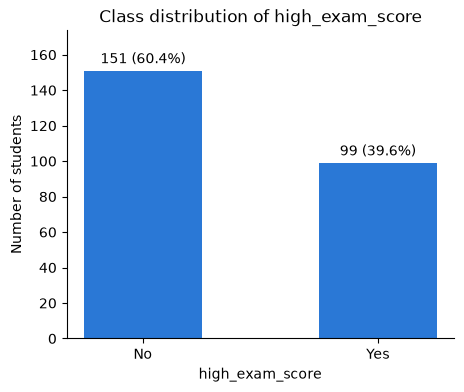

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(class_table.index, class_table["count"], width=0.5, color="#2a78d6")

# Label each bar with its count and percentage
labels = [f"{count} ({percent}%)" for count, percent in zip(class_table["count"], class_table["percent"])]
ax.bar_label(bars, labels=labels, padding=3)

ax.set_title("Class distribution of high_exam_score")
ax.set_xlabel("high_exam_score")
ax.set_ylabel("Number of students")
ax.set_ylim(0, class_table["count"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Part 1 Questions

**1. What are you trying to predict?**

**My answer:** We are trying to predict a high exam score. Whether a student gets a high score if exam_score >= 80. Prediction is made from student habits, before the exam happens. 

**2. Why is this a classification problem?**

**My answer:** This is a classification problem because the target has two discrete Yes and No labels. The model picks a category of these, not a number. 

**3. What percentage of students belong to each class?**

**My answer:** No = 60.4%, Yes = 39.6%

**4. Is the dataset approximately balanced?**

**My answer:** Not perfectly, it is a 60/40 split more or less. Mildly imbalanced

## Part 2 — Define X and y
Choose the feature columns, separate the features (X) from the target (y), and sort the features into numerical and categorical.

In [8]:
# Excluded on purpose: student_id, exam_score, and quiz_average are NOT features.
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

X = df[feature_columns]
y = df["high_exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250, 7)
y shape: (250,)


In [9]:
X.dtypes

study_hours_per_week            float64
sleep_hours_per_night           float64
attendance_rate                 float64
practice_problems_per_week        int64
prior_programming_experience        str
study_group                         str
commute_minutes                   int64
dtype: object

In [10]:
# Number columns are numerical. Text columns are categorical.
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['study_hours_per_week', 'sleep_hours_per_night', 'attendance_rate', 'practice_problems_per_week', 'commute_minutes']
Categorical features: ['prior_programming_experience', 'study_group']


### Part 2 Questions

**1. Why would using exam_score be target leakage?**

**My answer:** Using exam_score would be considered leakage because this isn't information the model has at the time of a prediction. THis model's purpose is TO predict exam_score, based on other features of students. Using exam_score would cause perfect accuracy in cross_validation, but tells you nothing about how habits relate to exam scores to learn further. 

## Part 3 — Train/Test Split
Split the data 80/20. `stratify=y` keeps the same Yes/No mix in both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (200, 7)
X_test:  (50, 7)
y_train: (200,)
y_test:  (50,)


In [12]:
# Class percentages should be nearly the same in all three columns
split_percents = pd.DataFrame({
    "full data": y.value_counts(normalize=True) * 100,
    "y_train": y_train.value_counts(normalize=True) * 100,
    "y_test": y_test.value_counts(normalize=True) * 100,
}).round(1)
split_percents

,full data,y_train,y_test
high_exam_score,,,
No,60.4,60.5,60.0
Yes,39.6,39.5,40.0


> ⚠️ **The test set is now locked away until Part 15.**
>
> `X_test` and `y_test` are not used for any model comparison, tuning, or experiment before Part 15. Every comparison from here on uses cross-validation on the training set only.

### Part 3 Questions

**1. Why are we holding the test set aside?**

**My answer:** If we were to use the test set, then it would cause more or less leakage. This test set stands in for future unseen students. The test set is for one final check at the end to compare our model. 

**2. What could happen if we repeatedly check test accuracy while modifying our model?**

**My answer:** If we did this, then the model will be tuned to those 50 specific students in the test set. The model becomes overly optimistic. 

## Part 4 — Preprocessing Pipeline
One `preprocessor` handles missing values, scaling, and one-hot encoding. `make_pipeline_for(model)` attaches it to any model so every model gets identical preprocessing.

In [13]:
# Numerical columns: fill blanks with the median, then scale to mean 0 and std 1
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical columns: fill blanks with the most common value, then one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [14]:
def make_pipeline_for(model):
    """Return a Pipeline of a fresh copy of the preprocessor followed by the model."""
    # clone() gives each pipeline its own unfitted preprocessor, so pipelines never share fitted state
    return Pipeline([
        ("prep", clone(preprocessor)),
        ("model", model),
    ])

### Part 4 Questions

**1. Why should preprocessing be included inside the pipeline?**

**My answer:** Preprocessing shoudl be here because it's fit on training data only. The imputer's medians, the scaler's mean and std, and the encoder's categories are all learned values. Inside a pipeline, fit learns them from the training data only. 

**2. Why is this especially important when using cross-validation?**

**My answer:** This is useful because in each round of the CV, one fold plays the role of unseen data. If you preprocess the whole training set before CV, it leads to a small leak. 

**3. Which of the models in this assignment are sensitive to feature scaling?**

**My answer:** Logistic Regression is the most sensitive to this feature.

**4. Do Decision Trees and Random Forests generally require scaling?**

**My answer:** No, a tree splits one feature at a time with a threshold, so scaling changes that thresholds number, but not which students end up each side. This leads to the split and predictions being the same.

## Part 5 — Establish a Baseline
A majority-class baseline ignores every feature and always predicts the most common training label. Any real model has to beat it.

In [15]:
# One shared splitter: every model in this notebook is scored on these same 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [16]:
baseline = make_pipeline_for(DummyClassifier(strategy="most_frequent"))

baseline_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="accuracy")

for fold, score in enumerate(baseline_scores, start=1):
    print(f"Fold {fold} accuracy: {score:.3f}")
print(f"Mean accuracy: {baseline_scores.mean():.3f}")
print(f"Std accuracy:  {baseline_scores.std():.3f}")

Fold 1 accuracy: 0.625
Fold 2 accuracy: 0.600
Fold 3 accuracy: 0.600
Fold 4 accuracy: 0.600
Fold 5 accuracy: 0.600
Mean accuracy: 0.605
Std accuracy:  0.010


### Part 5 Questions

**1. What does the baseline do?**

**My answer:** The baseline ignores every feature. During fit, it only counts which label is most common in the training forlds. It is a reference point. 

**2. What is its mean CV accuracy?**

**My answer:** .605 or 60.5%. 

**3. Why should our machine-learning models be compared with this baseline?**

**My answer:** Because it sets the bar, and is easy to compare if our models are better or worse than the baseline. 

## Part 6 — Understand Cross-Validation
The 200 training students are split into 5 folds. The model is trained 5 times. Each time, one fold is held out for validation and the other 4 are used for training.

```
Fold 1: VALIDATE | train    | train    | train    | train
Fold 2: train    | VALIDATE | train    | train    | train
Fold 3: train    | train    | VALIDATE | train    | train
Fold 4: train    | train    | train    | VALIDATE | train
Fold 5: train    | train    | train    | train    | VALIDATE
```

Every training student is used for validation exactly once. The test set is not part of any fold.

In [17]:
for fold, (train_rows, val_rows) in enumerate(cv.split(X_train, y_train), start=1):
    y_val = y_train.iloc[val_rows]
    percent_yes = (y_val == "Yes").mean() * 100
    print(f"Fold {fold}: {len(train_rows)} training rows, {len(val_rows)} validation rows, "
          f"{percent_yes:.1f}% Yes in validation")

Fold 1: 160 training rows, 40 validation rows, 37.5% Yes in validation
Fold 2: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 3: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 4: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 5: 160 training rows, 40 validation rows, 40.0% Yes in validation


### Part 6 Questions

**1. What happens during 5-fold cross-validation?**

**My answer:** The 200 students are split into 5 groups of 40 golds, and the model is trained 5 times. Each time, 4 folds are used to fit, and the last one is used to score. 

**2. How many times is each model trained?**

**My answer:** Each model is trained 5 times during CV, once per fold

**3. Why is cross-validation more informative than a single training/validation split?**

**My answer:** This is more informative because CV gives 5 numbers. The mean is more stable, and teh std tells you how much luck is involved. 

**4. Why do we still keep a separate final test set?**

**My answer:** CV scores are used to make choices. Once you pick the model with the best CV score, the score is slightly optimistic because you picked the winner. The test set wasn't used for any choice, so it gives an honest estimate at the end. 

## Part 7 — Create the Three Models
Each model gets the same preprocessing through `make_pipeline_for`. They are only defined here, not evaluated.

In [18]:
# Logistic Regression: weighs each feature and turns the total into a probability of "Yes"
log_reg = make_pipeline_for(LogisticRegression(max_iter=1000, random_state=42))

# Decision Tree: asks up to 4 levels of yes/no questions about the features to reach a prediction
tree_d4 = make_pipeline_for(DecisionTreeClassifier(max_depth=4, random_state=42))

# Random Forest: 200 decision trees, each trained on a random sample of students, that vote on the answer
rf = make_pipeline_for(RandomForestClassifier(n_estimators=200, random_state=42))

## Part 8 — Compare the Models with Cross-Validation
All four models are scored on the same `cv` folds with the same three metrics. "Yes" is the positive class.

In [19]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Yes", zero_division=0),
}


def evaluate_cv(name, pipeline):
    """Cross-validate a pipeline on the training set and return one row of the comparison table."""
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    # cross_validate names its keys "test_...", but these are the validation folds, NOT X_test
    return {
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std. Accuracy": scores["test_accuracy"].std(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
    }

In [20]:
comparison = pd.DataFrame([
    evaluate_cv("Majority baseline", baseline),
    evaluate_cv("Logistic Regression", log_reg),
    evaluate_cv("Decision Tree (depth 4)", tree_d4),
    evaluate_cv("Random Forest", rf),
]).round(3)
comparison

,Model,Mean CV Accuracy,Std. Accuracy,Mean Precision,Mean Recall
0,Majority baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.740,0.064,0.728,0.571
2,Decision Tree (depth 4),0.670,0.040,0.598,0.493
3,Random Forest,0.690,0.072,0.642,0.518


> **Use cautious language.** Each mean comes from only 5 folds of about 40 students, so one student changes a fold's accuracy by about 0.025. If the difference between two models is small compared with their Std. Accuracy, say they perform *similarly* or *slightly better*, not that one is clearly better.

### Part 8 Questions

**1. Which model has the highest mean CV accuracy?**

**My answer:** Logistic Regression, .740.

**2. How large are the differences?**

**My answer:** LR vs RF : .050. LR vs tree : .070. 

**3. Which model has the highest recall?**

**My answer:** Logistic Regression

**4. Do all metrics identify the same model?**

**My answer:** Yes, in this table, LR is highest on accuracy, precision, and recall. Stability however, the tree model is more consistent on stability. 

**5. How much does performance vary between folds?**

**My answer:** The baseline barely varies, std = .010. The real models vary more, std 0.040 (tree), .064 (LR), .072 (RF). 

## Part 9 — Hyperparameters

**In my own words (using max_depth as the example):**

A parameter is learned by fit() FROM the training data. However, a hyperparameter is a setting you choose BEFORE training. It controls how the model learns. Max_depth limits how many questions in a row the tree could ask. This is never changed by fit() or any other part during training. Because fit() can't choose hyperparameters, you compare values with cross-validation, never with the test set. 

## Part 10 — Experiment with Decision-Tree Depth
Try several `max_depth` values with the same `cv` folds. `return_train_score=True` also records accuracy on the training folds, so the two can be compared.

In [21]:
depths = [1, 2, 3, 4, 6, 8, None]
rows = []

for depth in depths:
    tree = make_pipeline_for(DecisionTreeClassifier(max_depth=depth, random_state=42))
    scores = cross_validate(tree, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    rows.append({
        "max_depth": str(depth),  # None becomes the string "None"
        "Training Accuracy": scores["train_score"].mean(),
        "CV Accuracy": scores["test_score"].mean(),  # validation folds, not X_test
        "CV Std": scores["test_score"].std(),
    })

depth_results = pd.DataFrame(rows)
depth_results.round(3)

,max_depth,Training Accuracy,CV Accuracy,CV Std
0,1,0.661,0.560,0.066
1,2,0.712,0.625,0.057
2,3,0.772,0.610,0.051
3,4,0.826,0.670,0.040
4,6,0.925,0.615,0.056
5,8,0.979,0.620,0.043
6,None,1.000,0.595,0.060


## Part 11 — Visualize Model Complexity
Training accuracy vs CV accuracy for each depth. The shaded band is ±1 CV std around the CV line.

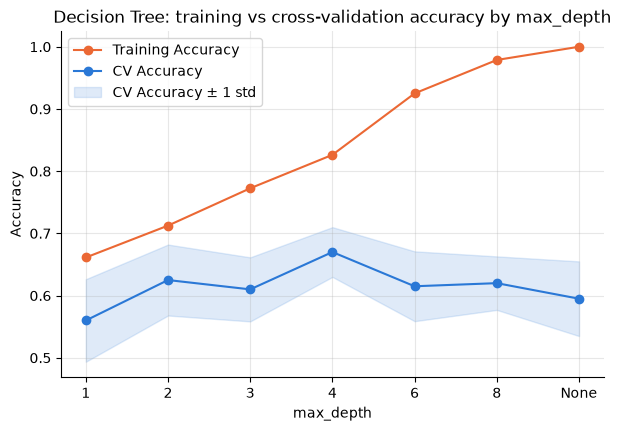

In [22]:
# Plot at even positions 0, 1, 2, ... and label them with the depth names
positions = range(len(depth_results))
cv_mean = depth_results["CV Accuracy"]
cv_std = depth_results["CV Std"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(positions, depth_results["Training Accuracy"], marker="o", color="#eb6834", label="Training Accuracy")
ax.plot(positions, cv_mean, marker="o", color="#2a78d6", label="CV Accuracy")
ax.fill_between(positions, cv_mean - cv_std, cv_mean + cv_std, color="#2a78d6", alpha=0.15, label="CV Accuracy ± 1 std")

ax.set_xticks(positions, depth_results["max_depth"])
ax.set_title("Decision Tree: training vs cross-validation accuracy by max_depth")
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Part 11 Questions

**1. What happens to training accuracy as max_depth increases?**

**My answer:** As max depth increases, accuracy increases every single step. With no depth limit, the accuracy reaches 100%. 

**2. What happens to cross-validation accuracy?**

**My answer:** It's not a linear increase, it doesn't follow training accuracy. Like max_depth = 3 the CV accuracy is .610, but max_depth 2 is .625, and max_depth = 4 is .670. 

**3. At what depth does the tree appear to perform best on unseen data?**

**My answer:** Depth 4 has the highest mean CV accuracy, and lowest std. 

**4. Do you see evidence of underfitting?**

**My answer:** Yes, at depth 1. Training accuracy is only .661, CV accuracy is .560, which is below the baseline. 

**5. Do you see evidence of overfitting?**

**My answer:** Yes, from depth 6 onward, training accuracy shoots up, while CV accuracy stays around 5.9-6.2

## Part 12 — Underfitting and Overfitting

| Pattern | Training accuracy | Validation (CV) accuracy | What it means |
|---|---|---|---|
| Underfitting | Poor | Poor | The model is too simple to capture the pattern |
| Good generalization | Good | Good (close to training) | The model learned a pattern that carries over to new students |
| Overfitting | Very high | Noticeably lower | The model memorized the training students, including noise |

A large gap between training and CV accuracy is the main sign of overfitting.

In [23]:
depth_results["Gap (Train − CV)"] = depth_results["Training Accuracy"] - depth_results["CV Accuracy"]
depth_results.round(3)

,max_depth,Training Accuracy,CV Accuracy,CV Std,Gap (Train − CV)
0,1,0.661,0.560,0.066,0.101
1,2,0.712,0.625,0.057,0.088
2,3,0.772,0.610,0.051,0.162
3,4,0.826,0.670,0.040,0.156
4,6,0.925,0.615,0.056,0.310
5,8,0.979,0.620,0.043,0.359
6,None,1.000,0.595,0.060,0.405


### Part 12 Questions

**1. Which Decision Tree depth appears to underfit?**

**My answer:** Depth 1 appears to underfit. Low training and low CV

**2. Which depth appears to generalize best?**

**My answer:** Depth 4 has the highest CV, and lowest CV std. But depth 2 has the smallest gap being .088

**3. Do the deepest trees show signs of overfitting?**

**My answer:** The deepest trees do show signs of overfitting, gaps of .310, .359, and .405. THe gap grows with every extra level past depth 4, and CV accuracy does not increase to account for it. 

**4. Why should we not simply choose the tree with the highest training accuracy?**

**My answer:** Highest training accuracy is deptn none, which has the worst CV score. Training accuracy measures how well the model fits students it has already seen, and it rewards memorizing. 

## Part 13 — Select a Decision-Tree Depth
Depths whose mean CV accuracy is within one CV std of the top score are "roughly tied": the difference is small compared with how much the score varies between folds.

In [24]:
ranked = depth_results.sort_values("CV Accuracy", ascending=False).reset_index(drop=True)

top_mean = ranked.loc[0, "CV Accuracy"]
top_std = ranked.loc[0, "CV Std"]
cutoff = top_mean - top_std

ranked["Roughly tied with top"] = np.where(ranked["CV Accuracy"] >= cutoff, "Yes", "No")

print(f"Top mean CV accuracy: {top_mean:.3f} (std {top_std:.3f})")
print(f"Roughly tied: CV accuracy of at least {top_mean:.3f} - {top_std:.3f} = {cutoff:.3f}")
ranked.round(3)

Top mean CV accuracy: 0.670 (std 0.040)
Roughly tied: CV accuracy of at least 0.670 - 0.040 = 0.630


,max_depth,Training Accuracy,CV Accuracy,CV Std,Gap (Train − CV),Roughly tied with top
0,4,0.826,0.670,0.040,0.156,Yes
1,2,0.712,0.625,0.057,0.088,No
2,8,0.979,0.620,0.043,0.359,No
3,6,0.925,0.615,0.056,0.310,No
4,3,0.772,0.610,0.051,0.162,No
5,None,1.000,0.595,0.060,0.405,No
6,1,0.661,0.560,0.066,0.101,No


In [25]:
chosen_depth = 4  # TODO: set this after reading the table

**My chosen depth and reasoning (mean CV performance, variability, model complexity):**

I chose depth 4, this is because depth 4 has the highest mean CV performance, and also the most consistent across folds. It has the lowest std of .040, meaning it is very consistent. I think the complexity trade off is worth it, since depth 4 is much more complex compared to depth 2 (4 leaves vs 2). 

## Part 14 — Compare the Tuned Tree Again
Same `cv` folds and the same three metrics as Part 8, now with the tuned tree added. Still no test set.

In [26]:
tuned_tree = make_pipeline_for(DecisionTreeClassifier(max_depth=chosen_depth, random_state=42))

final_comparison = pd.DataFrame([
    evaluate_cv("Majority baseline", baseline),
    evaluate_cv("Logistic Regression", log_reg),
    evaluate_cv("Decision Tree (depth 4)", tree_d4),
    evaluate_cv(f"Tuned Decision Tree (depth = {chosen_depth})", tuned_tree),
    evaluate_cv("Random Forest", rf),
]).round(3)
final_comparison

,Model,Mean CV Accuracy,Std. Accuracy,Mean Precision,Mean Recall
0,Majority baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.740,0.064,0.728,0.571
2,Decision Tree (depth 4),0.670,0.040,0.598,0.493
3,Tuned Decision Tree (depth = 4),0.670,0.040,0.598,0.493
4,Random Forest,0.690,0.072,0.642,0.518


In [27]:
final_model_name = "Logistic Regression"  # TODO: copy one model name exactly from the Model column above

**Based only on CV results, the model I will carry forward is Logistic Regression because it has all of the highest statistics out of the 4 models.**

## Part 15 — Final Test Evaluation
> 🔓 **The test set is now unlocked.** The model chosen in Part 14 is fit **once** on all of the training data and evaluated **once** on the test set. No other model is tried on the test set.

In [28]:
# Look up the pipeline for the model named in Part 14
models = {
    "Majority baseline": baseline,
    "Logistic Regression": log_reg,
    "Decision Tree (depth 4)": tree_d4,
    f"Tuned Decision Tree (depth = {chosen_depth})": tuned_tree,
    "Random Forest": rf,
}
final_model = models[final_model_name]

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, pos_label="Yes")
test_recall = recall_score(y_test, y_pred, pos_label="Yes")

print(f"Final model: {final_model_name}")
print(f"Test accuracy:  {test_accuracy:.3f}")
print(f"Test precision: {test_precision:.3f}")
print(f"Test recall:    {test_recall:.3f}")

Final model: Logistic Regression
Test accuracy:  0.840
Test precision: 0.875
Test recall:    0.700


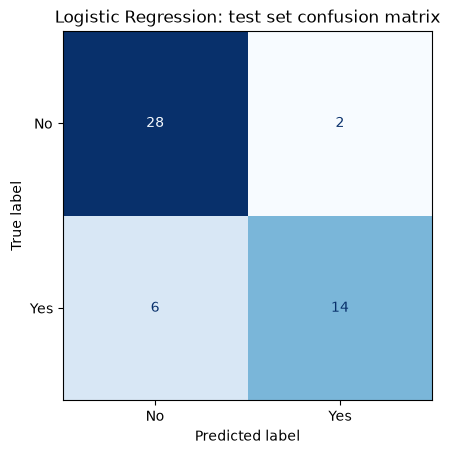

In [29]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["No", "Yes"], cmap="Blues", colorbar=False)
plt.title(f"{final_model_name}: test set confusion matrix")
plt.show()

In [30]:
# Majority-class baseline on the test set: always predict the most common TRAINING class
majority_class = y_train.value_counts().idxmax()
majority_test_accuracy = (y_test == majority_class).mean()
print(f"Most common training class: {majority_class}")
print(f"Majority-class test accuracy: {majority_test_accuracy:.3f}")

Most common training class: No
Majority-class test accuracy: 0.600


In [31]:
cv_row = final_comparison[final_comparison["Model"] == final_model_name].iloc[0]

cv_vs_test = pd.DataFrame({
    "CV mean (Part 14)": [cv_row["Mean CV Accuracy"], cv_row["Mean Precision"], cv_row["Mean Recall"]],
    "Test result": [test_accuracy, test_precision, test_recall],
}, index=["Accuracy", "Precision", "Recall"]).round(3)
cv_vs_test

,CV mean (Part 14),Test result
Accuracy,0.740,0.840
Precision,0.728,0.875
Recall,0.571,0.700


### Part 15 Questions

**1. How does final test accuracy compare with mean CV accuracy?**

**My answer:** Test accuracy .840 is .100 higher than the CV mean of .740. This is 42/50 correct. 

**2. Is it reasonably consistent with CV?**

**My answer:** This is reasonably consistent with my CV. It's within the range CV showed was a possibility, and it is not lower than the CV. 

**3. Did the model outperform the majority-class baseline?**

**My answer:** The model did outperform, .840 vs .600. Gain of .24.

**4. Are precision and recall similar to the CV results?**

**My answer:** Prevision and recall are both highe ron the test set, precision .875 vs .728, and recall .700 vs .571. The pattern is the same as CV, where prevision > recall.

## Part 16 — Analyze the Final Errors
Which test students did the final model get wrong?

In [32]:
test_results = X_test.copy()
test_results["actual"] = y_test
test_results["predicted"] = y_pred

false_positives = test_results[(test_results["predicted"] == "Yes") & (test_results["actual"] == "No")]
false_negatives = test_results[(test_results["predicted"] == "No") & (test_results["actual"] == "Yes")]
correct = test_results[test_results["predicted"] == test_results["actual"]]

print("False positives (predicted Yes, actually No):", len(false_positives))
print("False negatives (predicted No, actually Yes):", len(false_negatives))
print("Correct predictions:", len(correct))

False positives (predicted Yes, actually No): 2
False negatives (predicted No, actually Yes): 6
Correct predictions: 42


In [33]:
# exam_score is looked up from df for context only. The model never saw it.
false_positives.head(5).join(df["exam_score"])

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,actual,predicted,exam_score
132,9.7,5.7,92.9,13,Some,Yes,0,No,Yes,66.8
169,9.4,7.5,98.3,19,None,No,45,No,Yes,79.6


In [34]:
false_negatives.head(5).join(df["exam_score"])

,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,actual,predicted,exam_score
113,10.3,6.0,89.5,9,Some,No,38,Yes,No,88.6
80,5.6,7.6,87.3,36,None,No,28,Yes,No,87.9
140,9.4,7.0,82.8,13,Some,No,31,Yes,No,85.0
37,5.5,7.1,78.3,22,Some,Yes,19,Yes,No,80.1
89,NaN,6.2,72.7,15,Strong,No,28,Yes,No,82.0


In [35]:
# Mean of each numeric feature for each group (blank values are skipped)
group_means = pd.DataFrame({
    "False positives": false_positives[numeric_features].mean(),
    "False negatives": false_negatives[numeric_features].mean(),
    "Correct": correct[numeric_features].mean(),
}).round(2)
group_means

,False positives,False negatives,Correct
study_hours_per_week,9.55,7.30,7.86
sleep_hours_per_night,6.60,6.85,6.89
attendance_rate,95.60,82.22,85.91
practice_problems_per_week,16.00,19.00,17.19
commute_minutes,22.50,26.33,22.19


> **Avoid causal language.** These are patterns in a handful of mistakes, not causes. Write "the missed students *tended to have* lower attendance", not "low attendance *caused* the mistakes" or "studying more *makes* students score higher".

### Part 16 Questions

**1. How many false positives occurred?**

**My answer:** 2 false positives occured

**2. How many false negatives occurred?**

**My answer:** 6 false negatives occured

**3. Do you notice any patterns among the mistakes?**

**My answer:** False positives looked like high scores on paper, and false negatives looked like average students. The model's mistakes are students whose habits didn't match their outcomes. 

**4. Are some observations likely more difficult to classify than others?**

**My answer:** Yes, students near the 80 cutoff are difficulty to classivy, because a student at 79.9 and 80.1 are nearly identical, yet are given opposite labels. Small habit differences cannot really separate them distinctly. 

## Part 17 — Why Not Tune Using the Test Set?

**Workflow 1: check TEST accuracy after every change**

```
Train a model
     ↓
Check TEST accuracy
     ↓
Change something (features, depth, model)
     ↓
Check TEST accuracy again
     ↓
Repeat until the TEST score looks good
```

**Workflow 2: choose with cross-validation, test once**

```
Training data
     ↓
Cross-validation
     ↓
Compare models
     ↓
Tune hyperparameters
     ↓
Select final model
     ↓
FINAL TEST (once)
```

### Part 17 Questions

**1. What is wrong with the first procedure?**

**My answer:**The test set is used to make decisions. After enough rounds, the model is fitted to the test set. This means the final test score looks better than the model really is. 

**2. How has the test set indirectly become part of model development?**

**My answer:** The model never trains on test rows directly, but you do. YOu look at test scores, and keep the features that raise them. 

**3. Why is the final test score no longer a completely independent evaluation?**

**My answer:** An independent evaluation needs data that had 0 influece on the model. After checks, the test set heped choose the model, so it isn't independent, even though the model itself wasn't directly affected. 

**4. Why is the second workflow preferable?**

**My answer:** The second workflow uses CV on the training set for comparing and tuning. The test set is used once, after every choice is made, so it's score is an honest estimate for new student. 

## Part 18 — Scaling and Different Models
Training data only. The same depth-2 tree is fit on `attendance_rate` twice: once raw and once standardized.

In [36]:
# attendance_rate has no blanks, but drop missing rows anyway so the demo is safe
demo_X = X_train[["attendance_rate"]].dropna()
demo_y = y_train.loc[demo_X.index]

scaler = StandardScaler()
demo_X_scaled = scaler.fit_transform(demo_X)

tree_raw = DecisionTreeClassifier(max_depth=2, random_state=42).fit(demo_X, demo_y)
tree_scaled = DecisionTreeClassifier(max_depth=2, random_state=42).fit(demo_X_scaled, demo_y)

In [37]:
# Leaf nodes have no split, so keep only the nodes that split on a feature
raw_thresholds = tree_raw.tree_.threshold[tree_raw.tree_.feature >= 0]
scaled_thresholds = tree_scaled.tree_.threshold[tree_scaled.tree_.feature >= 0]

# Undo the scaling: original = scaled * std + mean
converted_back = scaled_thresholds * scaler.scale_[0] + scaler.mean_[0]

threshold_table = pd.DataFrame({
    "Raw threshold": raw_thresholds,
    "Scaled threshold": scaled_thresholds,
    "Scaled, converted back": converted_back,
}).round(3)
threshold_table

,Raw threshold,Scaled threshold,"Scaled, converted back"
0,91.60,0.646,91.60
1,80.75,-0.480,80.75
2,98.15,1.326,98.15


In [38]:
raw_predictions = tree_raw.predict(demo_X)
scaled_predictions = tree_scaled.predict(demo_X_scaled)

matching = (raw_predictions == scaled_predictions).sum()
print(f"Identical predictions: {matching} of {len(demo_X)} training rows")
print("Same cut points after converting back:", np.allclose(raw_thresholds, converted_back, atol=1e-4))

Identical predictions: 200 of 200 training rows
Same cut points after converting back: True


### Part 18 Questions

**1. Why is scaling useful for Logistic Regression?**

**My answer:** Scaling is useful because LR multiplies each feature by a coefficient and adds them, so scaling allows regression to punish features more fairly, since it punishes based on coefficient values. It leads to less punishment, with mean 0 and std 1. 

**2. Why do Decision Trees generally not require scaling?**

**My answer:** They do not generally need scaling because a tree asks one feature at a time, like is attendance <= 80. Scaling changes the number, but not the order of students, so the same students go left and right. 

**3. Why do Random Forests generally not require scaling?**

**My answer:** Random forests don't require scaling for similar reasons. A forest i sjust a collection of decision trees. Since trees are not affected by scaling, neither are forests. 

## Part 19 — Your Controlled Experiment

* compare 5-fold CV with 10-fold CV;
This is the experiment i want to choose. 

MY hypothesis is :

 I expect that using a 10 fold CV compared to a 5 fold CV will lead to higher accuracy and reliable performance estimate. I think this because each fold will use 10% of the data for training, and 90% for testing. The models train on more data 90%, leading to a lower bias.

**The one factor changed:** the number of folds (5 vs 10). Everything else stays identical: the same training data, the same three models from Part 7, the same preprocessing, `shuffle=True`, and `random_state=42`. The 5-fold side is the shared `cv` from Part 5. Test set not used.

In [39]:
cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rows = []
for name, pipeline in [("Logistic Regression", log_reg), ("Decision Tree (depth 4)", tree_d4), ("Random Forest", rf)]:
    for folds, splitter in [(5, cv), (10, cv_10)]:
        scores = cross_val_score(pipeline, X_train, y_train, cv=splitter, scoring="accuracy")
        rows.append({
            "Model": name,
            "Folds": folds,
            "Training rows per fold": len(X_train) * (folds - 1) // folds,
            "Mean CV Accuracy": scores.mean(),
            "Std. Accuracy": scores.std(),
        })

fold_results = pd.DataFrame(rows)
fold_results.round(3)

,Model,Folds,Training rows per fold,Mean CV Accuracy,Std. Accuracy
0,Logistic Regression,5,160,0.740,0.064
1,Logistic Regression,10,180,0.735,0.092
2,Decision Tree (depth 4),5,160,0.670,0.040
3,Decision Tree (depth 4),10,180,0.650,0.089
4,Random Forest,5,160,0.690,0.072
5,Random Forest,10,180,0.670,0.100


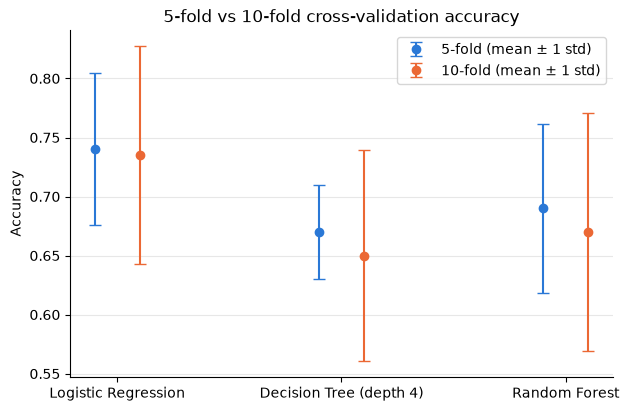

In [40]:
fig, ax = plt.subplots(figsize=(7, 4.5))
model_names = fold_results["Model"].unique()
positions = np.arange(len(model_names))

for folds, color, shift in [(5, "#2a78d6", -0.1), (10, "#eb6834", 0.1)]:
    subset = fold_results[fold_results["Folds"] == folds]
    ax.errorbar(positions + shift, subset["Mean CV Accuracy"], yerr=subset["Std. Accuracy"],
                fmt="o", color=color, capsize=4, label=f"{folds}-fold (mean ± 1 std)")

ax.set_xticks(positions, model_names)
ax.set_title("5-fold vs 10-fold cross-validation accuracy")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Results and whether they support my hypothesis:**

Overall, the results I got did not fully support my hypothesis. My hypothesis was that a 10 CV fold would have higher would have a higher accuracy. From the results, my 10-fold had slightly lower means on all 3 models, along with a higher std. I think this happened because the overall set is too small. More training should usually result in better model accuracy, but since each fold was only trained on 180 compared to 160, leading to an effect too small to see under noise. On this specific dataset, 10-fold also doubles the computation for no benefit. 

UNDERSTANDING CROSS-VALIDATION

## Part 20 — AI Reflection

### What did you ask?

**My answer:** At the start of the project outside of claude code, I asked what cross validation really meant. I saw an 80/20 split on the slides, and didn't really understand it 

### What did the AI recommend?

**My answer:** The AI gave me an explanation of what it is, and also gave issues with an 80/20 split like we use in here. AI giving me this information helped me to deepen my understanding of this method of comparing models, and how normally an 80/20 split would be a negative, but with cross validation, that issue is fixed. 

### Did you accept the recommendation?

**My answer:** I accepted all of the information the AI gave, and used it in my implementation and progression of this assignment, at least when it comes to cross validation information specifically. There are other points a long the project where I didn't choose AI recommendations. 

### How did you verify it?

**My answer:** I verified it by comparing the information I got to the class slides, and also did some basic google searches for similar responses. 

### Did you simplify or modify the AI's proposed solution?

**My answer:** I did not modify anything, but as I progressed through the project, my understanding of cross validation deepened, especially with my part 19 experiment of testing a 10 fold cv

### What did you learn?

**My answer:** I learned that AI can be a very good tool for learning concepts at a base level, and using them throughout an assignment or project can even further understanding, prompted by the AIs work. 

### Did the AI ever suggest using the test set while comparing or tuning models? If so, what did you do?

**My answer:** No. At the start of the assignment prompt, I specifically told Claude to not ever use or suggest using the test set until I explicitely said "PArt 15". Having streamlined prompts really helped with this assignment. 